# Axis 1 — Cache Capacity vs Working Set (Windows dGPU / PyTorch)

**Question.** At what cache capacity **K** does the working set saturate, and when does adding memory stop paying off?

**Hypothesis (from the team page).** At small caches (*K < 8*) the system is purely I/O-bound. Beyond a knee near *K ≈ 24* the hit rate plateaus because tail experts are rarely activated, and the bottleneck shifts from storage bandwidth to GPU compute.

> **Units.** OLMoE routes every token to 8 experts *per layer*, so "K < 8" and "K ≈ 24" only make sense **per layer**. This notebook sweeps the **global** K over all 1,024 logical `(layer, expert_id)` experts and reports the per-layer equivalent K/16. The hypothesis points are therefore global **K = 128** (8/layer) and **K = 384** (24/layer). On the dGPU, **K is the number of experts in VRAM**.

## What is measured
| Metric | How |
|---|---|
| Hit rate (overall, prefill, decode) | real cache counters; extended to every K by exact trace replay |
| Decode throughput, TTFT | wall clock, every step synchronised (`.item()` on the next token) |
| I/O vs non-I/O time | time loading misses vs everything else; loads split into **disk read** and **host → VRAM copy** |
| Working set W(τ) | distinct experts touched in τ consecutive generated tokens |
| Memory | bank bytes (exactly K × 12.6 MB, BF16) in VRAM, CUDA peak allocation, process RSS |
| Cold vs steady state | first request (empty cache) vs the rest |

## The cache is real
Only the non-expert weights (~0.95 GB) are loaded, into VRAM. The 12.9 GB expert bank stays in the safetensors files on disk; there is no copy of it in RAM either. A cache of capacity K is a preallocated bank of K slots **in VRAM**. A miss reads that expert's bytes from disk with **unbuffered I/O** (`FILE_FLAG_NO_BUFFERING`, so the Windows file cache never holds the bank) into a pinned staging buffer, then copies them into the slot on a CUDA stream. Disk-read time and host-to-VRAM copy time are recorded separately. Expert compute is transformers' own per-expert loop, run over the slot bank. See `src/moe/torch_cache.py`.

**Same workload as the Mac.** Same prompts (`prompts.json`), same K values, 12 requests × 64 new tokens. `MOE_SMOKE=1` runs a tiny configuration for a quick check.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Shared code: the `moe` package in src/. `pip install -e ".[windows]"` installs it; the path
# line below makes the notebook work without installing.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'moe').is_dir())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from moe import common, torch_cache as tc, results as rs, figures as fg   # tc is Windows (PyTorch)
for m in (common, tc, rs, fg):
    importlib.reload(m)                # pick up edits to src/moe without restarting the kernel

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-1-cache-capacity'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-1-cache-capacity') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

DEVICE = 'windows-dgpu'                 # results file: <axis>/results/windows-dgpu.json
AXIS = 'axis-1-cache-capacity'
TABLES = {}                             # every table this run produces, saved at the end

GPU = tc.default_device()               # the dedicated GPU (Windows + CUDA only); K counts experts in its VRAM
torch.set_grad_enabled(False)

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(tc.system_info(GPU))

Full run | results -> experiments\axis-1-cache-capacity\results
{'os': 'Windows-11-10.0.26300-SP0', 'cpu': 'Intel64 Family 6 Model 183 Stepping 1, GenuineIntel', 'ram_GB': 16.8, 'python': '3.14.7', 'torch': '2.11.0+cu128', 'transformers': '5.22.2', 'device': 'cuda', 'expert_reads': 'windows-unbuffered', 'gpu': 'NVIDIA GeForce RTX 5050 Laptop GPU', 'vram_GB': 8.55, 'cuda': '12.8'}


## Configuration

In [2]:
K_VALUES = [64, 96, 128, 192, 256, 384, 512, 768, 1024]   # global K in VRAM (per-layer = K/16)
POLICY = 'LRU'                 # Axis 1 holds the policy fixed; Axis 2 varies it
PROMPTS_PER_DOMAIN = 3         # x 4 kinds = 12 requests served back to back (max 4)
MAX_NEW_TOKENS = 64            # fixed length: EOS does not stop generation

if SMOKE:
    K_VALUES, PROMPTS_PER_DOMAIN, MAX_NEW_TOKENS = [64, 256], 1, 8

print('Global K   :', K_VALUES)
print('Per-layer  :', [k / 16 for k in K_VALUES])
CONFIG = rs.config_from(globals())   # recorded in the results file

Global K   : [64, 96, 128, 192, 256, 384, 512, 768, 1024]
Per-layer  : [4.0, 6.0, 8.0, 12.0, 16.0, 24.0, 32.0, 48.0, 64.0]


## Model (non-expert weights only) and correctness gate

In [3]:
MODEL_DIR = tc.default_model_dir()       # allenai/OLMoE-1B-7B-0125-Instruct (BF16), downloaded beforehand
assert list(MODEL_DIR.glob('model*.safetensors')),     f'Checkpoint not found in {MODEL_DIR}: download allenai/OLMoE-1B-7B-0125-Instruct there first.'
model, tokenizer, index = tc.load_model(MODEL_DIR, device=GPU)
print(index.describe())
print(f'Non-expert weights resident on {GPU}: {tc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| expert reads: {tc.ExpertReader(index).mode}')
# Measured ONCE, before any expert bank exists: free VRAM read later in the run is unreliable.
SAFE_K = tc.max_safe_capacity(index, GPU)
print(f'Largest K that fits in the VRAM free right now: {SAFE_K} (bank {SAFE_K * index.expert_bytes / 1e9:.1f} GB)')

# Correctness gate: one layer through the K-slot bank vs the stock transformers layer
# (all 64 experts of that layer resident, eager expert loop). Must be bit-identical.
diff = tc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock transformers: max |diff| = {diff}')

W1109 14:00:33.379000 34416 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


16 layers x 64 experts = 1024 logical experts | 12.58 MB each (BF16) | full bank 12.9 GB on disk
Non-expert weights resident on cuda: 0.95 GB | expert reads: windows-unbuffered
Largest K that fits in the VRAM free right now: 453 (bank 5.7 GB)
Layer exactness vs stock transformers: max |diff| = 0.0


## Workload
Axis 1 asks how big the working set of *ordinary serving traffic* is, so its workload is a mix of four kinds of request (math word problems, coding tasks, everyday chat, writing), **interleaved** so the cache sees mixed traffic as a server would. The prompts are in `prompts.json` (the same on every device); the same requests are served at every K.

In [4]:
# Mixed serving traffic: four kinds of request, interleaved, as a chat server would see.
prompt_file = rs.load_prompts(AXIS_DIR)   # axis-1-cache-capacity/prompts.json, shared by every device
PROMPTS = prompt_file['PROMPTS']
workload = tc.requests(PROMPTS, n_per_domain=PROMPTS_PER_DOMAIN, order='interleave')
wl = pd.DataFrame({'domain': [p['domain'] for p in workload],
                   'prompt_tokens': [len(tc.chat_tokens(tokenizer, p['text'])) for p in workload],
                   'prompt': [p['text'][:70] for p in workload]})
print(f'{len(workload)} requests, {wl.prompt_tokens.sum()} prompt tokens, '
      f'{len(workload) * MAX_NEW_TOKENS} generated tokens per K')
wl

12 requests, 377 prompt tokens, 768 generated tokens per K


,domain,prompt_tokens,prompt
0,math,43,A train leaves at 9:40 and arrives at 13:15. I...
1,code,34,Write a Python function that returns the k mos...
2,chat,27,What are some good ways to stay focused while ...
3,writing,30,Write a short story about a lighthouse keeper ...
4,math,41,A shop sells pens at 3 for $2. How much do 45 ...
5,code,36,Implement an LRU cache class in Python with ge...
6,chat,26,Can you explain the difference between weather...
7,writing,25,Write a persuasive paragraph arguing that citi...
8,math,31,The sum of three consecutive even numbers is 1...
9,code,31,Write a SQL query that finds the second highes...


## Real runs
For every K whose bank fits in the VRAM free at load (`SAFE_K`): allocate a fresh K-slot bank, serve the whole workload, and record every MoE call. Larger K values are **not timed**; their hit rates come from the exact replay below.

In [5]:
real_K = [k for k in K_VALUES if k <= SAFE_K]
replay_only_K = [k for k in K_VALUES if k > SAFE_K]
assert real_K, f'No K fits in free VRAM (largest safe K = {SAFE_K}). Close other GPU programs and re-run.'
print(f'Timed (real) runs: {real_K}')
print(f'Replay only (bank would not fit in VRAM): {replay_only_K}')

runs, per_prompt, traces, occupancy = {}, [], {}, {}
for K in real_K:
    tc.free_memory(); tc.reset_peak_memory(GPU)
    cache = tc.ExpertCache(index, K, POLICY, device=GPU)
    print(f'\nK = {K} (per layer {K / 16:g}) | bank {cache.bank_bytes / 1e9:.2f} GB in VRAM | '
          f'reads: {cache.reader.mode}')
    t0 = time.perf_counter()
    df, rec = tc.run_workload(model, tokenizer, cache, workload, MAX_NEW_TOKENS)
    wall = time.perf_counter() - t0

    s = cache.summary()
    assert s['resident'] <= K and len(cache.free) + s['resident'] == K   # never more than K experts
    df['K'] = K
    per_prompt.append(df)
    runs[K] = {**s, **tc.memory_snapshot(GPU), 'wall_s': wall, 'reads': cache.reader.mode}
    traces[K] = rec.events
    occupancy[K] = np.bincount([l for l, _ in cache.slot_of], minlength=index.num_layers)
    cache.close(); tc.detach_cache(model); del cache; tc.free_memory()

per_prompt = pd.concat(per_prompt, ignore_index=True)

# The cache must never change the model's output.
texts = per_prompt.groupby('K')['text'].apply(tuple)
assert texts.nunique() == 1, 'generated text differs between K values!'
print('\nGenerated text is identical at every K (the cache is exact).')

Timed (real) runs: [64, 96, 128, 192, 256, 384]
Replay only (bank would not fit in VRAM): [512, 768, 1024]

K = 64 (per layer 4) | bank 0.81 GB in VRAM | reads: windows-unbuffered
  [1/12] math             43 tok | TTFT   4.16s |  1.52 tok/s | hit   0.0% | io  41.15s of  45.47s
  [2/12] code             34 tok | TTFT   4.32s |  1.57 tok/s | hit   0.0% | io  40.27s of  44.39s
  [3/12] chat             27 tok | TTFT   3.77s |  1.65 tok/s | hit   0.0% | io  38.88s of  42.02s
  [4/12] writing          30 tok | TTFT   3.82s |  1.64 tok/s | hit   0.0% | io  39.07s of  42.14s
  [5/12] math             41 tok | TTFT   3.97s |  1.65 tok/s | hit   0.0% | io  39.13s of  42.22s
  [6/12] code             36 tok | TTFT   3.66s |  1.64 tok/s | hit   0.0% | io  38.88s of  42.01s
  [7/12] chat             26 tok | TTFT   3.78s |  1.63 tok/s | hit   0.0% | io  39.17s of  42.42s
  [8/12] writing          25 tok | TTFT   3.82s |  1.65 tok/s | hit   0.0% | io  39.00s of  42.10s
  [9/12] math             31

## Exact replay: hit rate at every K
Routing does not depend on the cache (the outputs are identical), so the recorded access stream is the same at every K. Replaying it through the same LRU policy, with the same grouping and pinning rules, must reproduce the real cache's counters **exactly** — checked below for every timed K — and then gives the hit rate for K values too large to time.

In [6]:
events = traces[real_K[0]]
acc = tc.events_frame(events)
print(f'{len(acc):,} cache accesses | {acc[["layer", "eid"]].drop_duplicates().shape[0]} distinct experts touched')

for K in real_K:                       # replay == real, exactly
    pol = tc.make_policy(POLICY, K)
    hits = tc.replay(events, pol)
    assert int(hits.sum()) == runs[K]['hits'] and pol.evictions == runs[K]['evictions'], K
print('Replay reproduces the real cache exactly at K =', real_K)

hit_rows = []
for K in K_VALUES:
    hits = tc.replay(events, tc.make_policy(POLICY, K))
    for phase in ['all', 'prefill', 'decode']:
        m = np.ones(len(acc), bool) if phase == 'all' else (acc.phase == phase).to_numpy()
        hit_rows.append({'K': K, 'phase': phase, 'hit_rate': hits[m].mean()})
hit_curve = pd.DataFrame(hit_rows).pivot(index='K', columns='phase', values='hit_rate')
compulsory = acc[['layer', 'eid']].drop_duplicates().shape[0] / len(acc)
print(f'Compulsory (first-touch) miss share: {compulsory:.1%} -> best possible hit rate {1 - compulsory:.1%}')
hit_curve.style.format('{:.1%}')

107,096 cache accesses | 1024 distinct experts touched
Replay reproduces the real cache exactly at K = [64, 96, 128, 192, 256, 384]
Compulsory (first-touch) miss share: 1.0% -> best possible hit rate 99.0%


phase,all,decode,prefill
K,,,
64,0.0%,0.0%,0.0%
96,0.0%,0.0%,0.0%
128,34.9%,38.5%,0.7%
192,37.1%,40.8%,1.6%
256,47.4%,52.1%,3.4%
384,60.8%,66.3%,9.6%
512,72.5%,78.1%,19.4%
768,89.2%,93.2%,51.4%
1024,99.0%,99.9%,90.7%


## Results table

In [7]:
agg = per_prompt.groupby('K').agg(
    decode_tokens=('new_tokens', lambda s: (s - 1).sum()), decode_s=('decode_s', 'sum'),
    ttft_mean_s=('ttft_s', 'mean'), io_s=('io_s', 'sum'), disk_s=('disk_s', 'sum'), h2d_s=('h2d_s', 'sum'),
    wall_s=('wall_s', 'sum'), route_wait_s=('route_wait_s', 'sum'), GB_loaded=('GB_loaded', 'sum'))
agg['decode_tok_s'] = agg.decode_tokens / agg.decode_s
agg['io_share'] = agg.io_s / agg.wall_s
agg['bank_GB'] = [runs[k]['bank_GB'] for k in agg.index]
agg['peak_GB'] = [runs[k]['gpu_peak_GB'] for k in agg.index]
agg['ms_per_load'] = [runs[k]['ms_per_load'] for k in agg.index]
agg['ms_per_disk_read'] = [runs[k]['ms_per_disk_read'] for k in agg.index]
agg['ms_per_h2d'] = [runs[k]['ms_per_h2d'] for k in agg.index]

table = hit_curve.rename(columns=lambda c: f'hit_{c}').join(agg, how='left')
table.insert(0, 'K_per_layer', table.index / 16)
TABLES['summary'] = table.reset_index()
TABLES['per_request'] = per_prompt.drop(columns='text')
TABLES['runs'] = pd.DataFrame(list(runs.values()))

cols = ['K_per_layer', 'hit_all', 'hit_prefill', 'hit_decode', 'decode_tok_s', 'ttft_mean_s',
        'io_share', 'GB_loaded', 'bank_GB', 'peak_GB', 'ms_per_load', 'ms_per_disk_read', 'ms_per_h2d']
table[cols].style.format({'K_per_layer': '{:g}', 'hit_all': '{:.1%}', 'hit_prefill': '{:.1%}',
                          'hit_decode': '{:.1%}', 'decode_tok_s': '{:.2f}', 'ttft_mean_s': '{:.2f}',
                          'io_share': '{:.0%}', 'GB_loaded': '{:.1f}', 'bank_GB': '{:.2f}',
                          'peak_GB': '{:.2f}', 'ms_per_load': '{:.2f}', 'ms_per_disk_read': '{:.2f}',
                          'ms_per_h2d': '{:.2f}'}, na_rep='not timed')

,K_per_layer,hit_all,hit_prefill,hit_decode,decode_tok_s,ttft_mean_s,io_share,GB_loaded,bank_GB,peak_GB,ms_per_load,ms_per_disk_read,ms_per_h2d
K,,,,,,,,,,,,,
64,4,0.0%,0.0%,0.0%,1.63,3.85,92%,1347.6,0.81,1.78,4.35,3.08,1.26
96,6,0.0%,0.0%,0.0%,1.61,3.84,92%,1347.6,1.21,2.18,4.39,3.12,1.27
128,8,34.9%,0.7%,38.5%,2.49,3.86,89%,877.6,1.61,2.59,4.42,3.15,1.28
192,12,37.1%,1.6%,40.8%,2.58,3.85,89%,848.2,2.42,3.39,4.43,3.15,1.28
256,16,47.4%,3.4%,52.1%,3.09,3.79,87%,708.7,3.22,4.20,4.44,3.16,1.29
384,24,60.8%,9.6%,66.3%,4.17,3.56,84%,527.7,4.83,5.81,4.43,3.16,1.28
512,32,72.5%,19.4%,78.1%,not timed,not timed,not timed,not timed,not timed,not timed,not timed,not timed,not timed
768,48,89.2%,51.4%,93.2%,not timed,not timed,not timed,not timed,not timed,not timed,not timed,not timed,not timed
1024,64,99.0%,90.7%,99.9%,not timed,not timed,not timed,not timed,not timed,not timed,not timed,not timed,not timed


## Hit rate vs K

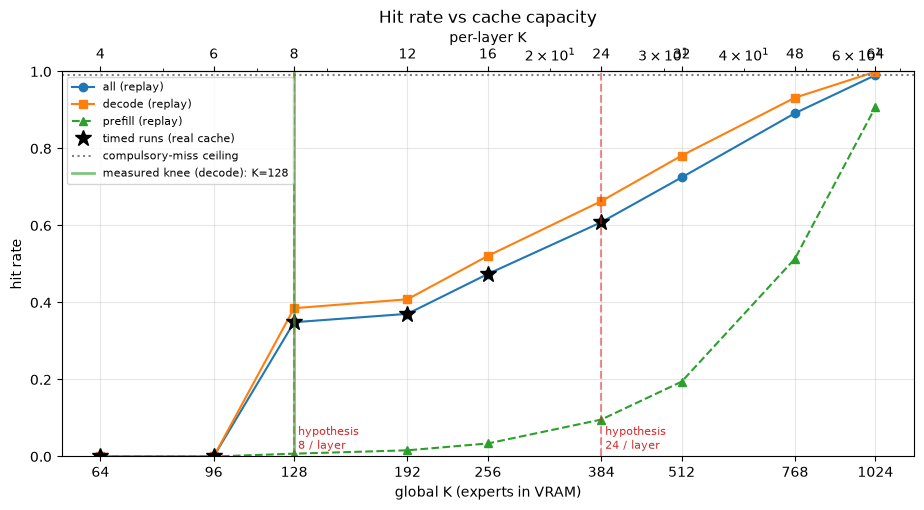

In [8]:
knee_K, _ = tc.knee_point(hit_curve.index.values, hit_curve['decode'].values)
fig, ax = plt.subplots()
for phase, style in [('all', '-o'), ('decode', '-s'), ('prefill', '--^')]:
    ax.plot(hit_curve.index, hit_curve[phase], style, label=f'{phase} (replay)')
ax.plot(real_K, [runs[k]['hit_rate'] for k in real_K], 'k*', ms=12, label='timed runs (real cache)')
ax.axhline(1 - compulsory, color='grey', ls=':', label='compulsory-miss ceiling')
for k, txt in [(128, '8 / layer'), (384, '24 / layer')]:
    ax.axvline(k, color='C3', ls='--', alpha=0.5)
    ax.text(k, 0.02, f' hypothesis\n {txt}', color='C3', fontsize=8)
ax.axvline(knee_K, color='C2', lw=2, alpha=0.6, label=f'measured knee (decode): K={knee_K:g}')
ax.set_xscale('log', base=2); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
sec = ax.secondary_xaxis('top', functions=(lambda k: k / 16, lambda k: k * 16))
sec.set_xticks([k / 16 for k in K_VALUES]); sec.set_xticklabels([f'{k / 16:g}' for k in K_VALUES])
sec.set_xlabel('per-layer K')
ax.set_xlabel('global K (experts in VRAM)'); ax.set_ylabel('hit rate'); ax.set_ylim(0, 1)
ax.legend(loc='upper left', fontsize=8); ax.set_title('Hit rate vs cache capacity')
plt.show()

## Throughput, latency and where the time goes

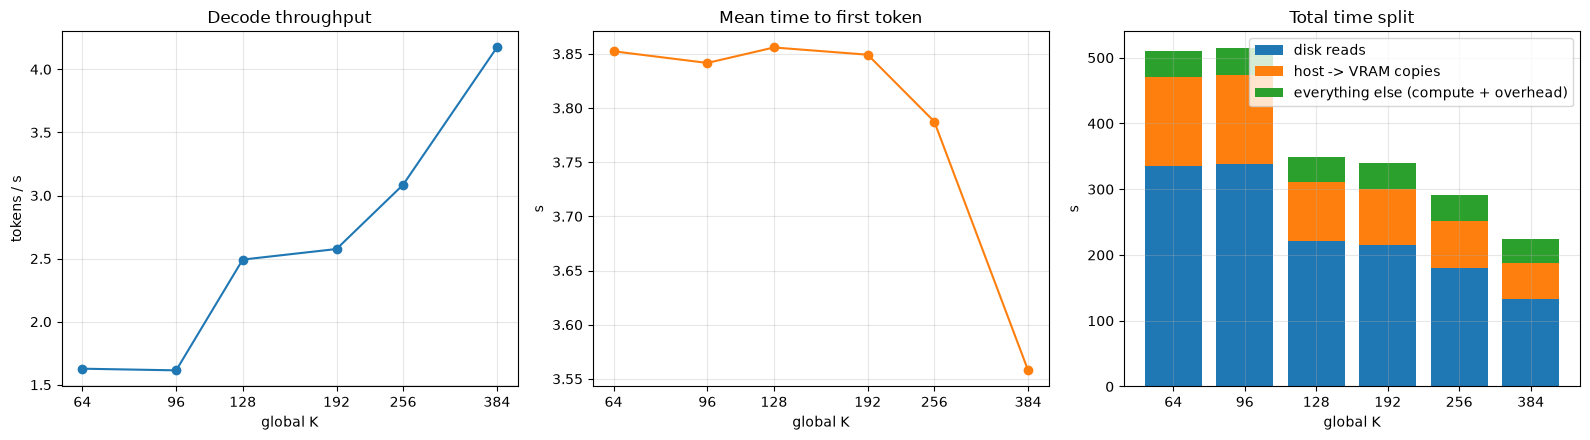

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
a = agg.loc[real_K]
axes[0].plot(a.index, a.decode_tok_s, '-o'); axes[0].set_title('Decode throughput'); axes[0].set_ylabel('tokens / s')
axes[1].plot(a.index, a.ttft_mean_s, '-o', color='C1'); axes[1].set_title('Mean time to first token'); axes[1].set_ylabel('s')
x = [str(k) for k in a.index]
axes[2].bar(x, a.disk_s, label='disk reads')
axes[2].bar(x, a.h2d_s, bottom=a.disk_s, label='host -> VRAM copies')
axes[2].bar(x, a.wall_s - a.io_s, bottom=a.io_s, label='everything else (compute + overhead)')
axes[2].set_title('Total time split'); axes[2].set_ylabel('s'); axes[2].legend()
for ax in axes[:2]:
    ax.set_xscale('log', base=2); ax.set_xticks(real_K); ax.set_xticklabels(real_K); ax.set_xlabel('global K')
axes[2].set_xlabel('global K')
fig.tight_layout(); plt.show()

## Working set W(τ)
How many distinct experts does the model touch in τ consecutive generated tokens? A cache of size K can hold the working set of a window τ when W(τ) ≤ K, so the curve says how much "reuse distance" each K covers. It depends only on routing, so it should nearly match the Mac's curve.

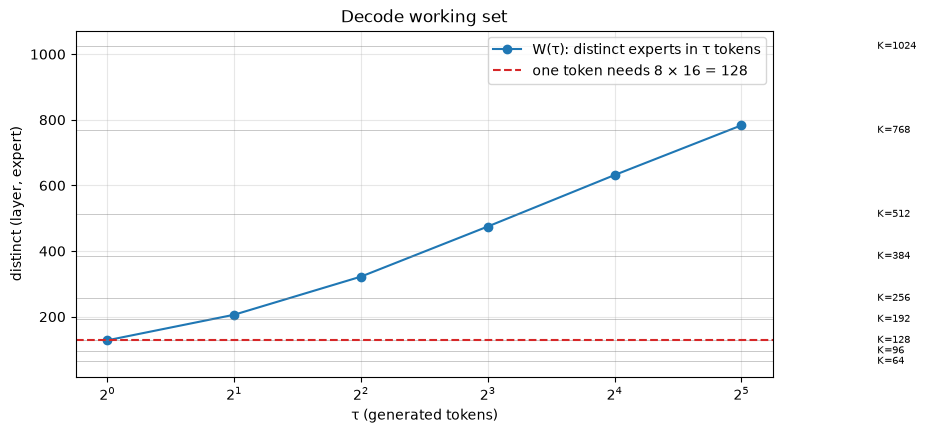

,1,2,4,8,16,32,64
W(tau),128.0,205.91129,322.066667,474.797619,631.652778,783.166667,NaN


In [10]:
taus = [1, 2, 4, 8, 16, 32, 64] if not SMOKE else [1, 2, 4]
ws = tc.working_set_curve(events, taus)
TABLES['working_set'] = pd.DataFrame({'tau': list(ws), 'W': list(ws.values())}).dropna()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(list(ws), list(ws.values()), '-o', label='W(τ): distinct experts in τ tokens')
for k in K_VALUES:
    ax.axhline(k, color='grey', lw=0.6, alpha=0.5)
    ax.text(taus[-1] * 1.05, k, f'K={k}', fontsize=7, va='center')
ax.axhline(16 * 8, color='C3', ls='--', label='one token needs 8 × 16 = 128')
ax.set_xscale('log', base=2); ax.set_xlabel('τ (generated tokens)'); ax.set_ylabel('distinct (layer, expert)')
ax.legend(); ax.set_title('Decode working set')
plt.show()
pd.Series(ws, name='W(tau)').to_frame().T

## Cold start vs steady state, and how a global cache splits across layers
Request 0 starts with an empty cache; later requests start warm. With a **global** K, layers compete for slots — the heat map shows how many slots each layer holds at the end of the run.

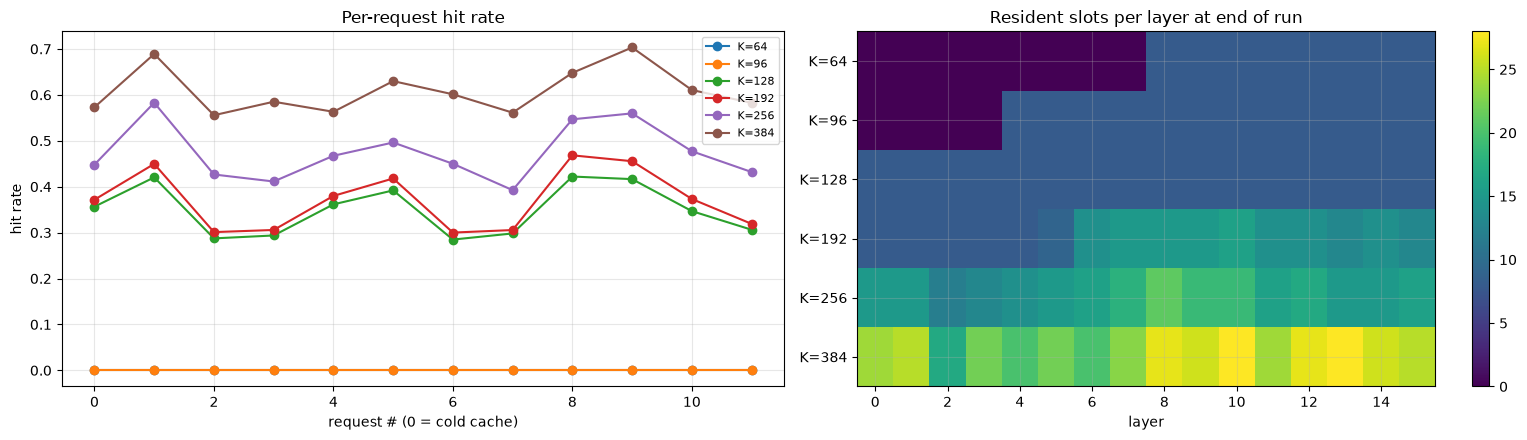

,cold (request 0),steady (requests 1+)
K,,
64,0.0%,0.0%
96,0.0%,0.0%
128,35.7%,34.8%
192,37.2%,37.0%
256,44.8%,47.6%
384,57.3%,61.2%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for K in real_K:
    d = per_prompt[per_prompt.K == K]
    axes[0].plot(d.prompt, d.hit_rate, '-o', label=f'K={K}')
axes[0].set_xlabel('request # (0 = cold cache)'); axes[0].set_ylabel('hit rate'); axes[0].legend(fontsize=8)
axes[0].set_title('Per-request hit rate')
occ = np.array([occupancy[k] for k in real_K])
im = axes[1].imshow(occ, aspect='auto', cmap='viridis')
axes[1].set_yticks(range(len(real_K))); axes[1].set_yticklabels([f'K={k}' for k in real_K])
axes[1].set_xlabel('layer'); axes[1].set_title('Resident slots per layer at end of run')
fig.colorbar(im, ax=axes[1]); fig.tight_layout()
plt.show()

cold = per_prompt[per_prompt.prompt == 0].set_index('K').hit_rate
warm = per_prompt[per_prompt.prompt > 0].groupby('K')[['hits', 'misses']].sum()
steady = warm.hits / (warm.hits + warm.misses)
pd.DataFrame({'cold (request 0)': cold, 'steady (requests 1+)': steady}).style.format('{:.1%}')

## Hypothesis check (descriptive)

In [12]:
small = [k for k in real_K if k / 16 < 8]
io_share = agg.io_share
cross = [k for k in real_K if io_share[k] < 0.5]
print(f'Measured knee of the decode hit-rate curve: K = {knee_K:g} ({knee_K / 16:g} per layer); '
      f'hypothesis said 384 (24 per layer).')
for k in small:
    print(f'K={k} ({k / 16:g}/layer): I/O is {io_share[k]:.0%} of total time -> '
          f'{"I/O-bound" if io_share[k] > 0.5 else "not I/O-bound"}')
if cross:
    print(f'I/O falls below half of the time from K = {cross[0]} ({cross[0] / 16:g}/layer).')
else:
    print('I/O stays above half of the time at every timed K.')
share_h2d = (agg.h2d_s / agg.io_s).loc[real_K]
print(f'Host -> VRAM copies are {share_h2d.min():.0%}-{share_h2d.max():.0%} of load time; the rest is the disk read.')
best = hit_curve['decode'].max()
for frac in (0.9, 0.95):
    kk = hit_curve.index[hit_curve['decode'] >= frac * best][0]
    print(f'{frac:.0%} of the best decode hit rate is reached at K = {kk} ({kk / 16:g}/layer).')

Measured knee of the decode hit-rate curve: K = 128 (8 per layer); hypothesis said 384 (24 per layer).
K=64 (4/layer): I/O is 92% of total time -> I/O-bound
K=96 (6/layer): I/O is 92% of total time -> I/O-bound
I/O stays above half of the time at every timed K.
Host -> VRAM copies are 29%-29% of load time; the rest is the disk read.
90% of the best decode hit rate is reached at K = 768 (48/layer).
95% of the best decode hit rate is reached at K = 1024 (64/layer).


## Notes for reading the results

* **Within-device trends first.** These are PyTorch / BF16 / CUDA numbers. The Mac runs MLX / F16 on unified memory: compare the *shape* of the curves across devices, not absolute values as one controlled experiment.
* **No page cache to purge.** Expert reads are unbuffered (`reads` = `windows-unbuffered` in the system info), so every miss really goes to the disk. If the reader had to fall back to buffered reads it prints a warning and the mode says `buffered`.
* **K is the VRAM tier.** The timed K values are those whose bank fits in the VRAM free at load (`SAFE_K`); larger K are replay-only (hit rates exact, no timing). Close other GPU programs before a full run.

* **Fixed-length generation.** Every request generates exactly `MAX_NEW_TOKENS`, so work is identical across K.

## Save results
Every table above goes into **one file for this device**: `results/windows-dgpu.json`, with the configuration, prompts and machine it ran on.
The Mac and Windows iGPU notebooks write `mac.json` / `windows-igpu.json` next to it in the same format (see `experiments/README.md`).

In [13]:
CONFIG['SAFE_K'] = globals().get('SAFE_K')
path = rs.save(RESULTS, AXIS, DEVICE, TABLES, config=CONFIG, prompts=rs.load_prompts(AXIS_DIR),
               system=tc.system_info(GPU))
print('Saved', path.relative_to(ROOT), '| tables:', {k: len(v) for k, v in TABLES.items()})

Saved experiments\axis-1-cache-capacity\results\windows-dgpu.json | tables: {'summary': 9, 'per_request': 72, 'runs': 6, 'working_set': 6}


## Cross-device figures
The report figures, drawn from every device's results file in this folder (colour = device). Only shown here;
`python -m moe.figures` writes them to `figures/` once all devices have results.

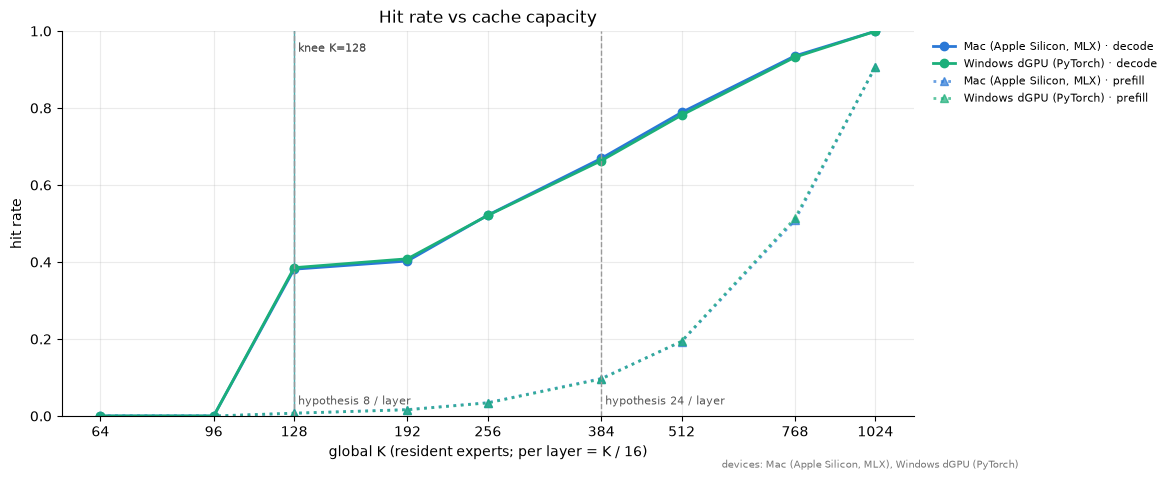

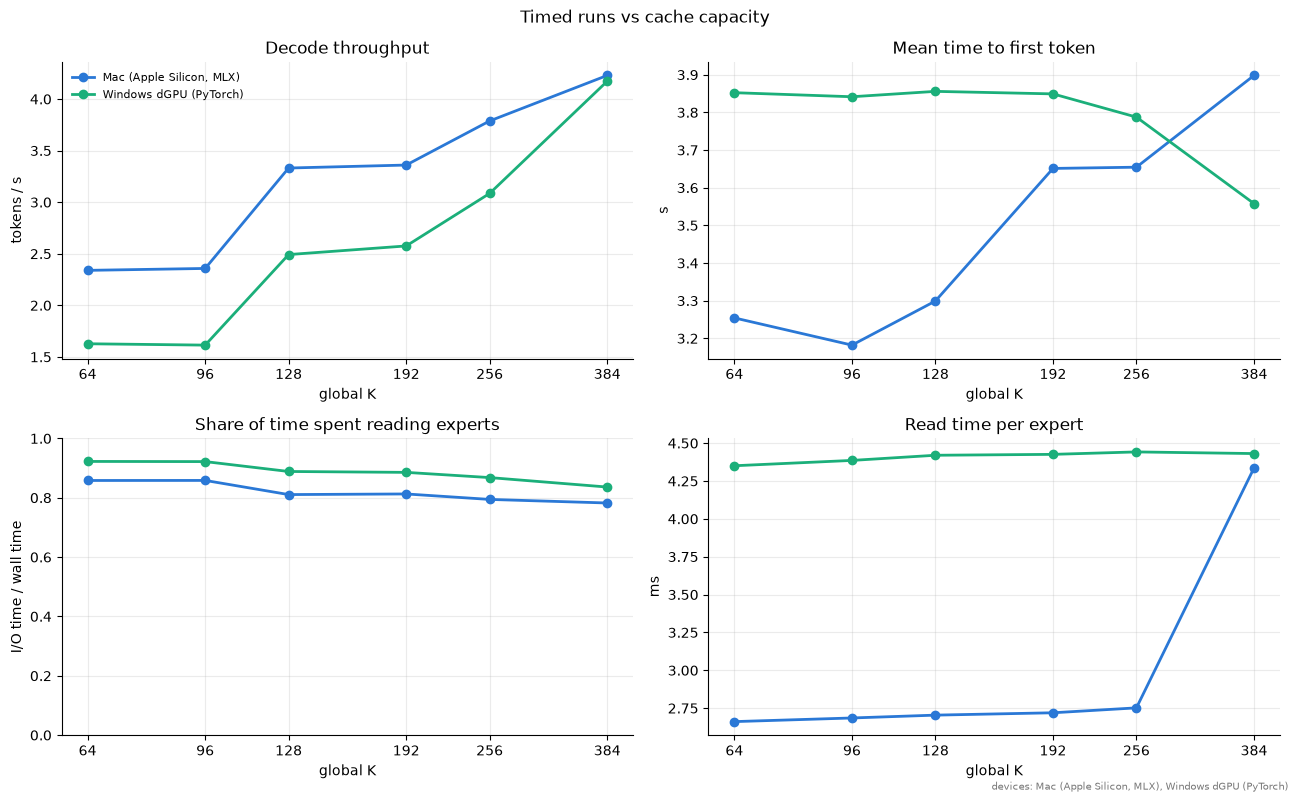

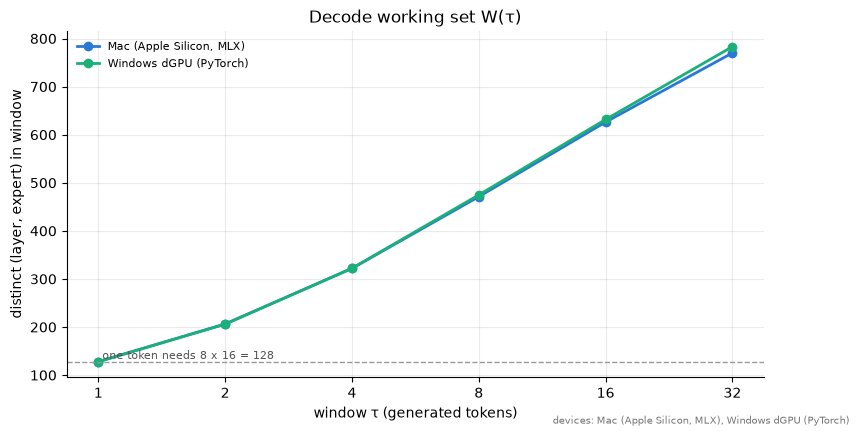

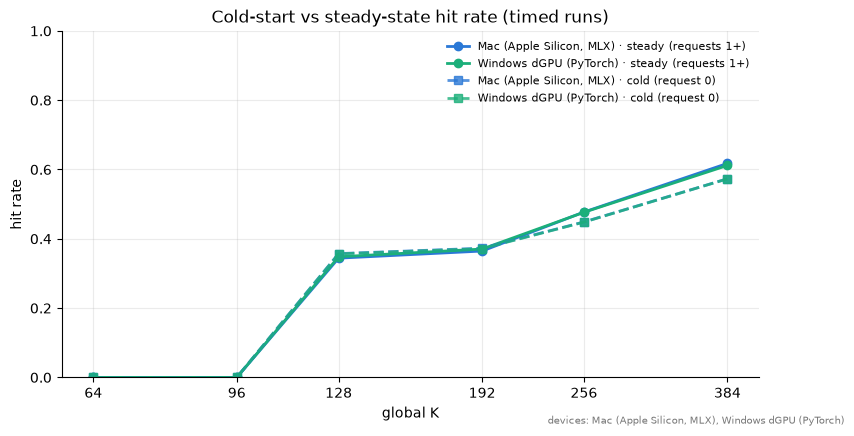

In [14]:
figs = fg.make(AXIS, RESULTS)